In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('../data/Seattle_Real_Time_Fire_911_Calls_20261029.csv')
# data/Seattle_Real_Time_Fire_911_Calls_20261029.csv
        
df.head()

,Address,Type,Datetime,Latitude,Longitude,Report Location,Incident Number
0,11501 15th Ave Ne,Auto Fire Alarm,2026 Oct 29 09:58:00 PM,47.712167,-122.312433,POINT (-122.312433 47.712167),F260155357
1,7044 54th Ave Ne,Aid Response,2026 Oct 29 09:56:00 PM,47.679687,-122.269560,POINT (-122.26956 47.679687),F260155354
2,12th Ave / E Alder St,Illegal Burn,2026 Oct 29 09:53:00 PM,47.604190,-122.316781,POINT (-122.316781 47.60419),F260155352
3,15th Ave E / E John St,Medic Response- 6 per Rule,2026 Oct 29 09:49:00 PM,47.619967,-122.312719,POINT (-122.312719 47.619967),F260155347
4,506 10th Ave E,Aid Response,2026 Oct 29 09:46:00 PM,47.623183,-122.319906,POINT (-122.319906 47.623183),F260155346


In [3]:
# Check the shape the current dataframe
df.shape

(2220491, 7)

In [4]:
# Check the NaN values
na_data_count = df.isna().sum()

na_data_count

Address             175
Type                  0
Datetime              0
Latitude           2256
Longitude          2256
Report Location    2178
Incident Number       0
dtype: int64

## datetime

The dataset from 2003 to up to data. And the seattle is changing the code over time, and 2020–2021 is unusual becuase COVID cut calls 16%, and 2021 was still recovering, so I suggested to keep the data from 2022.


We train on 2022 onward because call coding changed repeatedly between 2014 and 2022 and 2020–21 were affected by COVID. Yearly volume is stable at about 101–107k calls from 2022 to 2026. We use the full 2003–2026 history in the exploration tab to show long-term trends.


1. check the time period of the data
2. check the `NaN` values and convert the time to year, month and day in a month
3. identify the time period we want to use - 588170 rows

In [5]:
df['Datetime'] = pd.to_datetime(
    df['Datetime'],
    format='mixed',
    errors='coerce'
)

df['Datetime'].head()

0   2026-10-29 21:58:00
1   2026-10-29 21:56:00
2   2026-10-29 21:53:00
3   2026-10-29 21:49:00
4   2026-10-29 21:46:00
Name: Datetime, dtype: datetime64[us]

In [6]:
df['Datetime'].tail()

2220486   2003-11-07 09:56:10
2220487   2003-11-07 09:50:05
2220488   2003-11-07 09:43:15
2220489   2003-11-07 09:31:47
2220490   2003-11-07 09:30:48
Name: Datetime, dtype: datetime64[us]

In [7]:
df_year_unique = df['Datetime'].dt.year.unique()

df_year_unique

array([2026, 2025, 2024, 2023, 2022, 2021, 2020, 2019, 2018, 2017, 2016,
       2015, 2014, 2013, 2012, 2011, 2010, 2009, 2008, 2007, 2006, 2005,
       2004, 2003], dtype=int32)

In [8]:
data = df.copy()

datetime_na = data['Datetime'].isna().sum()

print(datetime_na)

0


In [9]:
# drop 2003 - 2021 since one shift start at 8AM and end at 8AM the next day
start = pd.Timestamp('2022-01-01 08:00')
end = pd.Timestamp('2026-10-29 08:00')

data = data[(data['Datetime'] >= start) & (data['Datetime'] < end)]

print(f"Length of data: ", len(data))
pd.to_datetime(data['Datetime']).dt.year.unique()


Length of data:  587823


array([2026, 2025, 2024, 2023, 2022], dtype=int32)

In [10]:
def clean_datatime():
    data['Datetime'] = pd.to_datetime(data['Datetime'])
    data['Date'] = data['Datetime'].dt.date
    data['Time'] = data['Datetime'].dt.time
    data['Year'] = data['Datetime'].dt.year
    data['Month'] = data['Datetime'].dt.month
    data['Day'] = data['Datetime'].dt.day
    data['Hour'] = data['Datetime'].dt.hour
    # return data.drop(columns='Datetime')
    return data

data = clean_datatime()

data.head()

,Address,Type,Datetime,Latitude,Longitude,Report Location,Incident Number,Date,Time,Year,Month,Day,Hour
224,171 12th Ave,Auto Fire Alarm,2026-10-29 07:50:00,47.603031,-122.316782,POINT (-122.316782 47.603031),F260154990,2026-10-29,07:50:00,2026,10,29,7
225,2655 Nw 86th St,Aid Response Yellow,2026-10-29 07:49:00,47.691308,-122.391040,POINT (-122.39104 47.691308),F260154989,2026-10-29,07:49:00,2026,10,29,7
226,6535 Seaview Ave Nw,Medic Response,2026-10-29 07:48:00,47.676031,-122.406369,POINT (-122.406369 47.676031),F260154988,2026-10-29,07:48:00,2026,10,29,7
227,11 W Aloha St,Aid Response,2026-10-29 07:41:00,47.627192,-122.356823,POINT (-122.356823 47.627192),F260154987,2026-10-29,07:41:00,2026,10,29,7
228,4123 California Ave Sw,Aid Response,2026-10-29 07:33:00,47.566398,-122.386771,POINT (-122.386771 47.566398),F260154985,2026-10-29,07:33:00,2026,10,29,7


### Why we drop Fast Back Up

Our target counts every call that comes into dispatch. We only drop records that dispatch creates for an incident it already has, because counting them would count the same call twice. Fast Back Up is one of these:

- The official SFD code table (`data/sfd-type-codes-standard-response.csv`) says `FASTB, Fast Back-up` sends only 1 Battalion Chief and 1 Safety Officer, with no engine, ladder, aid or medic unit. Every other type sends at least one unit that treats patients or fights fire.
- The check below shows that most Fast Back Up records come shortly after another call at the same address, mostly an Aid Response. Normal calls almost never do.

We have not found an official SFD definition of "FAST". There are only 88 rows from 2022 to 2026, so dropping them barely changes the daily count.

We run this check here because the next step drops `Address`.

In [11]:
# for each call, find the previous call at the same address
fb_check = data[['Datetime', 'Type', 'Address']].dropna().copy()
fb_check['addr'] = fb_check['Address'].str.upper().str.replace(r'\s+', ' ', regex=True).str.strip()
# at the same timestamp, put Fast Back Up after the other call
fb_check['is_fb'] = fb_check['Type'] == 'Fast Back Up'
fb_check = fb_check.sort_values(['addr', 'Datetime', 'is_fb'])
fb_check['prev_type'] = fb_check.groupby('addr')['Type'].shift()
fb_check['prev_gap_min'] = (fb_check['Datetime'] - fb_check.groupby('addr')['Datetime'].shift()).dt.total_seconds() / 60
fb_check['after_earlier_call'] = fb_check['prev_gap_min'] <= 60

is_fb = fb_check['is_fb']
fb = fb_check[is_fb]

print(f"Fast Back Up rows: {len(fb)}")
print(f"follow another call at the same address within 60 min: "
      f"Fast Back Up {fb['after_earlier_call'].mean():.1%} vs all other calls {fb_check.loc[~is_fb, 'after_earlier_call'].mean():.1%}")

gap = fb.loc[fb['after_earlier_call'], 'prev_gap_min']
print(f"minutes after the earlier call: median {gap.median():.0f}, IQR {gap.quantile(0.25):.0f}-{gap.quantile(0.75):.0f}")

fb.loc[fb['after_earlier_call'], 'prev_type'].value_counts().head(5).rename('earlier call type')

Fast Back Up rows: 88
follow another call at the same address within 60 min: Fast Back Up 83.0% vs all other calls 2.8%
minutes after the earlier call: median 12, IQR 8-19


prev_type
Aid Response                  34
Auto Fire Alarm                7
Medic Response                 4
Fast Back Up                   3
Medic Response- 7 per Rule     2
Name: earlier call type, dtype: int64

## Report Location and incident Number

Dropped columns `Report Location`, `Incident Number`, and `Address`:

- Report Location and Incident Number are not useful for the current prediction.
- Address provides redundant information.

In [12]:
data = data.drop(columns=['Report Location', 'Incident Number', 'Address'])

data.head()

,Type,Datetime,Latitude,Longitude,Date,Time,Year,Month,Day,Hour
224,Auto Fire Alarm,2026-10-29 07:50:00,47.603031,-122.316782,2026-10-29,07:50:00,2026,10,29,7
225,Aid Response Yellow,2026-10-29 07:49:00,47.691308,-122.391040,2026-10-29,07:49:00,2026,10,29,7
226,Medic Response,2026-10-29 07:48:00,47.676031,-122.406369,2026-10-29,07:48:00,2026,10,29,7
227,Aid Response,2026-10-29 07:41:00,47.627192,-122.356823,2026-10-29,07:41:00,2026,10,29,7
228,Aid Response,2026-10-29 07:33:00,47.566398,-122.386771,2026-10-29,07:33:00,2026,10,29,7


### Type

There are 168 types from 2022 to 2026. `data/sfd_type_mapping.csv` gives each type a `group` and a broader `model_group`, with a short reason for each. Groups come from the official SFD code table (`data/sfd-type-codes-standard-response.csv`), or from the type's name when the code is not in the table.

Our target is how many calls the dispatch center handles per shift, so we keep every call that comes into dispatch, including standby, referrals and mutual aid. We drop a type only if it is not a real call, or if the data shows dispatch created it for an incident it already had. "No SFD unit was sent" or "the event was scheduled" is not a reason to drop.

| model_group | groups |
|---|---|
| `medical` | `medical_bls` (basic, aid unit), `medical_als` (serious, needs a paramedic) |
| `fire` | `fire`, `alarm` (automatic alarms tie up units even when there is no fire) |
| `other` | `traffic`, `rescue`, `hazard_utility`, `unit_dispatch` (codes like 1RED–4RED that say how many units were sent, not what happened) |
| `non_emergency` | `referral`, `standby_event`, `mutual_aid`, `internal_admin` |
| `drop` | `drop_test` (TEST - MIS TEST), `followup` (Fast Back Up, see the check above) |

Notes:
- Triaged Incident and Nurseline/AMR (`referral`) stop after 2025-05-31, and no other code takes their place. We keep them for now and decide how the model handles them at the baseline stage.
- A type that suddenly drops to zero may have been recoded. For example, gas calls were recorded as 2RED from 2024-03 to 2025-12.
- Records with the same address and timestamp are kept. Each one has its own Incident Number and is a separate record handled by dispatch. They make up about 0.5% of records.

In [13]:
unique_types = data['Type'].unique()

with pd.option_context('display.max_rows', None):
    print(unique_types)

<ArrowStringArray>
[             'Auto Fire Alarm',          'Aid Response Yellow',
               'Medic Response',                 'Aid Response',
                 '2RED - 1 + 1',              'Rescue Elevator',
                  '1RED 1 Unit',   'Medic Response- 7 per Rule',
                 'Rubbish Fire',                 'Illegal Burn',
 ...
             'Encampment Medic',                   'HazMat MCI',
 'AFAHI - Auto Alarm High Rise',       '4RED - 2 + 1 + 1 Water',
              'Mayday Incident',       'Mutual Aid  Basic Life',
         'Tunnel Full Response',              'Hazardous Decon',
             'Fire With Rescue',           'Referral To Agency']
Length: 168, dtype: str


In [14]:
import plotly.graph_objects as go

# same chart without the two codes that stop after 2025-05-31
gone = ['Triaged Incident', 'Nurseline/AMR']
monthly = data[~data['Type'].isin(gone)].groupby(['Year', 'Month']).size().rename('calls').reset_index()

def days_covered(year, month):
    month_start = pd.Timestamp(year=year, month=month, day=1)
    month_end = month_start + pd.offsets.MonthBegin(1)
    return (min(month_end, end) - max(month_start, start)) / pd.Timedelta(days=1)

monthly['days'] = [days_covered(y, m) for y, m in zip(monthly['Year'], monthly['Month'])]
monthly['calls_per_day'] = monthly['calls'] / monthly['days']



# fixed categorical order, one color per year
year_colors = {2022: '#2a78d6', 2023: '#eb6834', 2024: '#1baf7a', 2025: '#eda100', 2026: '#e87ba4'}
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig = go.Figure()
for year, g in monthly.groupby('Year'):
    fig.add_trace(go.Scatter(
        x=[month_names[m - 1] for m in g['Month']], y=g['calls_per_day'],
        mode='lines+markers', name=str(year),
        line=dict(color=year_colors[year], width=2), marker=dict(size=8),
        customdata=g[['calls', 'days']],
        hovertemplate=f'{year}: ' + '%{y:.0f} calls/day<br>%{customdata[0]:,} calls in %{customdata[1]:.1f} days<extra></extra>',
    ))

fig.update_layout(
    title='Calls per day by month, without Triaged Incident and Nurseline/AMR',
    xaxis=dict(title=None, categoryorder='array', categoryarray=month_names, showgrid=False),
    yaxis=dict(title='Calls per day', gridcolor='#e6e6e3', zeroline=False),
    hovermode='x unified', plot_bgcolor='white', paper_bgcolor='white',
    font=dict(color='#333'), legend=dict(title='Year'),
)
fig.show()

In [15]:
is_stopped_referral = data['Type'].isin(['Triaged Incident', 'Nurseline/AMR'])

stopped_referral_by_year = pd.DataFrame({
    'total calls': data.groupby('Year').size(),
    'stopped referral calls': data[is_stopped_referral].groupby('Year').size(),
}).fillna(0).astype(int)
stopped_referral_by_year['calls without them'] = stopped_referral_by_year['total calls'] - stopped_referral_by_year['stopped referral calls']
stopped_referral_by_year


,total calls,stopped referral calls,calls without them
Year,,,
2022,119808,10533,109275
2023,125678,12051,113627
2024,129629,15181,114448
2025,119299,7065,112234
2026,93409,0,93409


In [16]:
type_map = pd.read_csv('../data/sfd_type_mapping.csv')

def clean_type():
    data['Group'] = data['Type'].map(dict(zip(type_map['type'], type_map['group'])))
    data['ModelGroup'] = data['Type'].map(dict(zip(type_map['type'], type_map['model_group'])))

data = data.copy()
clean_type()

# every type should have a group
print(data[['Group', 'ModelGroup']].isna().sum())

Group         0
ModelGroup    0
dtype: int64


In [17]:
group_summary = data.groupby(['ModelGroup', 'Group']).agg(types=('Type', 'nunique'), rows=('Type', 'size'))
group_summary['percentage'] = (group_summary['rows'] / len(data) * 100).round(2)
group_summary.sort_values('rows', ascending=False)

types    rows  percentage
ModelGroup    Group                                    
medical       medical_bls        12  317573       54.03
              medical_als        23   74092       12.60
fire          alarm              11   56220        9.56
non_emergency referral            8   49873        8.48
fire          fire               36   31493        5.36
other         unit_dispatch      11   20656        3.51
              traffic             5   14529        2.47
              rescue             14   11742        2.00
              hazard_utility     19    6893        1.17
non_emergency standby_event       8    3823        0.65
drop          drop_test           1     389        0.07
non_emergency mutual_aid         13     296        0.05
              internal_admin      6     154        0.03
drop          followup            1      90        0.02

In [18]:
# keep every incoming call; drop only TEST and Fast Back Up
calls = data[data['ModelGroup'] != 'drop'].copy()
print(len(calls))

587344


In [19]:
calls_na = calls.isna().sum()

calls_na

Type             0
Datetime         0
Latitude      1399
Longitude     1399
Date             0
Time             0
Year             0
Month            0
Day              0
Hour             0
Group            0
ModelGroup       0
dtype: int64

Since we can get the information about the lat and long, so we drop them directly

In [20]:

calls = calls.dropna()

calls.shape

(585945, 12)

## Area: station first-due areas

We forecast calls per fire station area, because SFD staffs and moves units by station, and a shift planner can act on "Station 10 will be busy". A 1 km grid is too sparse: 96.5% of grid cell-hours and 64% of grid cell-shifts have no call. Station areas per shift have only 1.8% empty.

- Stations: `data/sfd_stations.csv`, the 34 numbered stations from the [Seattle GIS Fire Stations](https://catalog.data.gov/dataset/fire-stations-62886) layer (HQ and Harborview left out).
- Each call goes to its nearest station. This is the same as drawing Voronoi polygons around the stations. Real first-due areas follow roads and bridges, so this is an approximation.
- City boundary: `data/seattle_area.geojson` ([Seattle Area Polygon](https://catalog.data.gov/dataset/seattle-area-polygon), which extends past the shoreline). About 0.3% of calls fall outside it, mostly just over the city line. We keep them, since dispatch handled them, and flag them with `InSeattle`.

In [21]:
import json
from matplotlib.path import Path
from sklearn.neighbors import BallTree

stations = pd.read_csv('../data/sfd_stations.csv')
seattle = Path(json.load(open('../data/seattle_area.geojson'))['features'][0]['geometry']['coordinates'][0])

# nearest station, same as a Voronoi area around each station
tree = BallTree(np.radians(stations[['lat', 'lon']].values), metric='haversine')
dist, idx = tree.query(np.radians(calls[['Latitude', 'Longitude']].values), k=1)
calls['Station'] = stations['station'].values[idx[:, 0]]
calls['StationDistKm'] = dist[:, 0] * 6371
calls['InSeattle'] = seattle.contains_points(calls[['Longitude', 'Latitude']].values)

print(f"outside Seattle: {(~calls['InSeattle']).sum()} calls ({(~calls['InSeattle']).mean():.2%})")
calls['StationDistKm'].describe(percentiles=[.5, .9, .99]).round(2)

outside Seattle: 1628 calls (0.28%)


count    585945.00
mean          0.83
std           0.57
min           0.02
50%           0.78
90%           1.45
99%           2.10
max          69.27
Name: StationDistKm, dtype: float64

## Shifts and feed outages

One SFD shift runs from 08:00 to 08:00 the next day, so a call at 03:00 belongs to the previous day's shift (`ShiftDate`).

Citywide, dispatch gets about 14 calls per hour, and even the quietest hours (3–5 AM) average 7–8 calls. At that rate we would expect only about 3 truly empty hours in five years, so an hour with no call anywhere in Seattle is almost certainly a gap in the data feed, not a quiet hour. We mark those hours as outages and mask any shift that contains one, so the model does not learn a fake low count. The 02:00 hour on the spring daylight-saving day does not exist on the clock, so it is not counted as an outage.

In [22]:
# a call at 03:00 belongs to the shift that started at 08:00 the day before
calls['ShiftDate'] = (calls['Datetime'] - pd.Timedelta(hours=8)).dt.normalize()

# hours with no call anywhere in the city
all_hours = pd.date_range(start, end, freq='h', inclusive='left')
city_hourly = calls.groupby(calls['Datetime'].dt.floor('h')).size().reindex(all_hours, fill_value=0)

# 02:00 on the spring daylight-saving day does not exist (clocks jump to 03:00), so it is not an outage
dst_skipped = all_hours.tz_localize('America/Los_Angeles', nonexistent='NaT',
                                    ambiguous=np.zeros(len(all_hours), dtype=bool)).isna()
outage_hours = city_hourly.index[(city_hourly == 0) & ~dst_skipped]
print(f"daylight-saving hours skipped: {dst_skipped.sum()}")

# group back-to-back outage hours into runs
runs = (outage_hours.to_series().diff() != pd.Timedelta(hours=1)).cumsum()
run_lengths = runs.value_counts()

outage_per_shift = (outage_hours - pd.Timedelta(hours=8)).normalize().value_counts()

print(f"outage hours: {len(outage_hours)} of {len(all_hours)} ({len(outage_hours) / len(all_hours):.2%})")
print(f"outage runs: {len(run_lengths)}, longest {run_lengths.max()} hours")
print(f"shifts with an outage hour: {len(outage_per_shift)} of {len(all_hours) // 24}")
outage_per_shift.value_counts().sort_index().rename_axis('outage hours in shift').rename('shifts')

daylight-saving hours skipped: 5
outage hours: 81 of 42288 (0.19%)
outage runs: 26, longest 14 hours
shifts with an outage hour: 24 of 1762


outage hours in shift
1     11
2      5
3      3
5      1
8      1
11     1
13     1
14     1
Name: shifts, dtype: int64

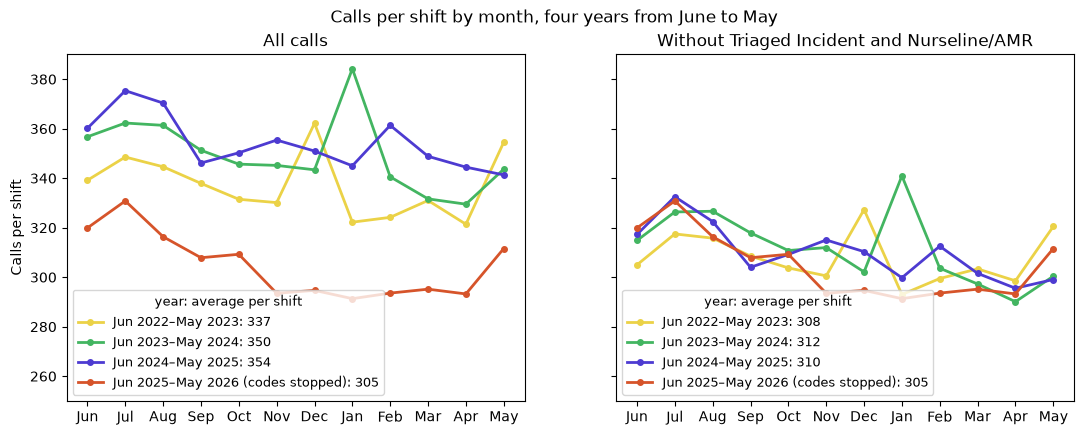

In [23]:
stopped = calls['Type'].isin(['Triaged Incident', 'Nurseline/AMR'])
month_order = ['Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec', 'Jan', 'Feb', 'Mar', 'Apr', 'May']
years = {'Jun 2022–May 2023': ('2022-06-01', '2023-05-31', "#ebd247"),
        'Jun 2023–May 2024': ('2023-06-01', '2024-05-31', "#43b561"),
         'Jun 2024–May 2025': ('2024-06-01', '2025-05-31', "#4d3bd1"),
         'Jun 2025–May 2026 (codes stopped)': ('2025-06-01', '2026-05-31', '#d6542a')}

def by_month(first, last, keep):
    """Calls per shift each month for the calls where keep is True."""
    p = calls['ShiftDate'].between(first, last)
    month = calls.loc[p, 'ShiftDate'].dt.strftime('%b')
    days = calls[p].groupby(month)['ShiftDate'].nunique()
    return (calls[p & keep].groupby(month).size() / days).reindex(month_order)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (title, keep) in zip(axes, [('All calls', pd.Series(True, index=calls.index)),
                                    ('Without Triaged Incident and Nurseline/AMR', ~stopped)]):
    for name, (first, last, color) in years.items():
        m = by_month(first, last, keep)
        ax.plot(month_order, m, color=color, marker='o', markersize=4, linewidth=2, label=f'{name}: {m.mean():.0f}')
    ax.set_title(title)
    ax.legend(loc='lower left', fontsize=9, title='year: average per shift', title_fontsize=9)
axes[0].set_ylabel('Calls per shift')
axes[0].set_ylim(250, 390)
fig.suptitle('Calls per shift by month, four years from June to May')
fig.savefig('../figures/four_years.png', dpi=200, bbox_inches='tight')
plt.show()


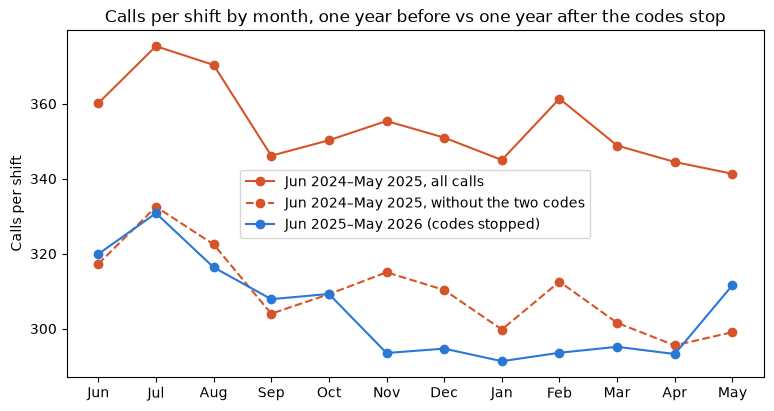

In [24]:
stopped = calls['Type'].isin(['Triaged Incident', 'Nurseline/AMR'])
month_order = ['Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec', 'Jan', 'Feb', 'Mar', 'Apr', 'May']

def calls_per_shift_by_month(first, last):
    """Calls per shift for each month, with and without the two codes."""
    in_period = calls['ShiftDate'].between(first, last)
    month = calls.loc[in_period, 'ShiftDate'].dt.strftime('%b')
    days = calls.loc[in_period].groupby(month)['ShiftDate'].nunique()
    return pd.DataFrame({
        'all': calls[in_period].groupby(month).size() / days,
        'without': calls[in_period & ~stopped].groupby(month).size() / days,
    }).reindex(month_order)

before = calls_per_shift_by_month('2024-06-01', '2025-05-31')   # codes still in use
after = calls_per_shift_by_month('2025-06-01', '2026-05-31')    # codes stopped

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(month_order, before['all'], color='#d6542a', marker='o', label='Jun 2024–May 2025, all calls')
ax.plot(month_order, before['without'], color='#d6542a', marker='o', linestyle='--',
        label='Jun 2024–May 2025, without the two codes')
ax.plot(month_order, after['all'], color='#2a78d6', marker='o', label='Jun 2025–May 2026 (codes stopped)')
ax.set_title('Calls per shift by month, one year before vs one year after the codes stop')
ax.set_ylabel('Calls per shift')
ax.legend()

fig.savefig('../figures/break_full_year.png', dpi=200, bbox_inches='tight')
plt.show()


In [25]:
# ---- prepare: drop the two stopped codes, add both levels of the mapping ----
stopped = calls['Type'].isin(['Triaged Incident', 'Nurseline/AMR'])
c = calls[~stopped].copy()
c['model_group'] = c['Type'].map(dict(zip(type_map['type'], type_map['model_group'])))
c['group'] = c['Type'].map(dict(zip(type_map['type'], type_map['group'])))


def per_shift(data, first, last, key):
    """Calls per shift in a period, one row per value of key."""
    w = data[data['ShiftDate'].between(first, last)]
    return w.groupby(key).size() / w['ShiftDate'].nunique()


def compare(data, key):
    """Nov–Mar one year apart, sorted so the biggest drop is on top."""
    t = pd.DataFrame({
        'Nov 2024–Mar 2025': per_shift(data, '2024-11-01', '2025-03-31', key),
        'Nov 2025–Mar 2026': per_shift(data, '2025-11-01', '2026-03-31', key),
    }).fillna(0)                                      # a code missing in one period counts as 0
    t['change'] = t.iloc[:, 1] - t.iloc[:, 0]
    return t.sort_values('change').round(1)


# ---- drill down: filter to the part that changed, then group by a finer column ----
print('Level 1: the four groups')
display(compare(c, 'model_group'))

print('Level 2: inside medical')
display(compare(c[c['model_group'] == 'medical'], 'group'))

print('Level 3: inside medical_bls')
display(compare(c[c['group'] == 'medical_bls'], 'Type'))


# ---- recode check: codes that disappear or appear, with their group ----
by_type = compare(c, 'Type')
by_type['group'] = by_type.index.map(dict(zip(type_map['type'], type_map['group'])))

print('Codes that changed by 1 or more per shift')
display(by_type[by_type['change'].abs() >= 1])

print('Codes that disappear')
display(by_type[by_type['Nov 2025–Mar 2026'] == 0])

print('Codes that appear')
display(by_type[by_type['Nov 2024–Mar 2025'] == 0])




Level 1: the four groups


,Nov 2024–Mar 2025,Nov 2025–Mar 2026,change
model_group,,,
medical,222.0,207.5,-14.5
fire,51.6,49.9,-1.8
non_emergency,4.6,5.1,0.6
other,29.5,31.2,1.7


Level 2: inside medical


,Nov 2024–Mar 2025,Nov 2025–Mar 2026,change
group,,,
medical_bls,181.5,168.3,-13.2
medical_als,40.5,39.2,-1.3


Level 3: inside medical_bls


,Nov 2024–Mar 2025,Nov 2025–Mar 2026,change
Type,,,
Aid Response,161.0,146.3,-14.7
Low Acuity Response,6.2,4.1,-2.1
Automatic Medical Alarm,3.5,3.2,-0.2
Scenes Of Violence Aid,0.2,0.1,-0.1
BC Aid Response Yellow,0.0,0.0,-0.0
BC Aid Response,0.1,0.1,-0.0
Aid Response Freeway,0.1,0.2,0.1
Hang-Up- Aid,0.5,0.8,0.3
Aid Response Yellow,9.9,13.5,3.6


... (2 outputs left out)

Codes that disappear


,Nov 2024–Mar 2025,Nov 2025–Mar 2026,change,group
Type,,,,
AFA4 - Auto Alarm 2 + 1 + 1,2.3,0.0,-2.3,alarm
Rescue Standby,0.1,0.0,-0.1,standby_event
Mutual Aid- Engine,0.1,0.0,-0.0,mutual_aid
Vault Advised,0.0,0.0,-0.0,hazard_utility
LINK - Link Control Center,0.0,0.0,-0.0,internal_admin
Chimney Fire,0.1,0.0,-0.0,fire
Vessel Sinking On Shore,0.0,0.0,-0.0,rescue
Vault Fire (Electrical),0.0,0.0,-0.0,fire
Mutual Aid- Medic,0.0,0.0,-0.0,mutual_aid


Codes that appear


,Nov 2024–Mar 2025,Nov 2025–Mar 2026,change,group
Type,,,,
Vault Advised,0.0,0.0,-0.0,hazard_utility
LINK - Link Control Center,0.0,0.0,-0.0,internal_admin
Vessel Sinking On Shore,0.0,0.0,-0.0,rescue
Vault Fire (Electrical),0.0,0.0,-0.0,fire
Mutual Aid- Medic,0.0,0.0,-0.0,mutual_aid
Rescue Heavy Major,0.0,0.0,-0.0,rescue
Multiple Casualty Incident,0.0,0.0,-0.0,medical_als
Hang-Up- Fire,0.0,0.0,-0.0,fire
BC Aid Response Yellow,0.0,0.0,-0.0,medical_bls


In [26]:
# Triaged Incident and Nurseline/AMR stop on 2025-05-31 with no replacement (see the checks above),
# so we remove them from the target to keep its meaning the same in training and test
stopped = calls['Type'].isin(['Triaged Incident', 'Nurseline/AMR'])
print(f"removed {stopped.sum():,} calls ({stopped.mean():.1%})")
calls = calls[~stopped].copy()

removed 44,626 calls (7.6%)


## Modeling table: calls per station per shift

One row per station per shift, with 0 for shifts with no calls. We keep a count for each `model_group` as well as the total, so we can still decide later whether to predict the total or each group, and how to handle the referral break after 2025-05-31. Shifts with a feed outage are flagged with `Masked` and left out of training and evaluation.

In [27]:
shift_dates = pd.date_range(start.normalize(), end.normalize() - pd.Timedelta(days=1), freq='D')
full_index = pd.MultiIndex.from_product([stations['station'], shift_dates], names=['Station', 'ShiftDate'])

# every station x shift, 0 when there was no call
table = (calls.pivot_table(index=['Station', 'ShiftDate'], columns='ModelGroup', values='Type', aggfunc='size', fill_value=0)
              .reindex(full_index, fill_value=0))
table.columns.name = None
table['calls'] = table.sum(axis=1)
table = table.reset_index()

table['OutageHours'] = table['ShiftDate'].map(outage_per_shift).fillna(0).astype(int)
table['Masked'] = table['OutageHours'] > 0

# every call should land in exactly one row
assert table['calls'].sum() == len(calls)
print(f"{table['Station'].nunique()} stations x {table['ShiftDate'].nunique()} shifts = {len(table)} rows")
print(f"masked rows: {table['Masked'].sum()} ({table['Masked'].mean():.1%})")
print(f"rows with 0 calls (unmasked): {(table.loc[~table['Masked'], 'calls'] == 0).mean():.1%}")

table.to_csv('../data/station_shift_counts.csv', index=False)
table.head()

34 stations x 1762 shifts = 59908 rows
masked rows: 816 (1.4%)
rows with 0 calls (unmasked): 2.1%


,Station,ShiftDate,fire,medical,non_emergency,other,calls,OutageHours,Masked
0,SFD 35,2022-01-01,1,2,1,0,4,0,False
1,SFD 35,2022-01-02,1,5,0,1,7,0,False
2,SFD 35,2022-01-03,0,5,0,0,5,0,False
3,SFD 35,2022-01-04,0,4,0,0,4,0,False
4,SFD 35,2022-01-05,0,5,1,2,8,0,False


In [28]:
# share of each station's calls by hour of the shift, for the app's hourly breakdown
# training years only, so the app can use it for any date from 2025-01-03 on
HISTORY_THROUGH = pd.Timestamp('2024-12-31')

masked_dates = table.loc[table['Masked'], 'ShiftDate'].unique()
h = calls[(calls['ShiftDate'] <= HISTORY_THROUGH) & ~calls['ShiftDate'].isin(masked_dates)].copy()
h['shift_hour'] = (h['Datetime'].dt.hour - 8) % 24          # 08:00 -> 0, 07:00 next day -> 23

counts = (h.groupby(['Station', 'shift_hour']).size()
           .reindex(pd.MultiIndex.from_product([stations['station'], range(24)],
                                               names=['Station', 'shift_hour']), fill_value=0))
profile = (counts / counts.groupby('Station').transform('sum')).rename('share').reset_index()
profile['history_through'] = HISTORY_THROUGH.date()

assert len(profile) == len(stations) * 24
assert np.allclose(profile.groupby('Station')['share'].sum(), 1)
profile.to_csv('../data/hourly_profile.csv', index=False)
profile.head(24)


,Station,shift_hour,share,history_through
0,SFD 35,0,0.041119,2024-12-31
1,SFD 35,1,0.047046,2024-12-31
2,SFD 35,2,0.048713,2024-12-31
3,SFD 35,3,0.049268,2024-12-31
4,SFD 35,4,0.045749,2024-12-31
5,SFD 35,5,0.056677,2024-12-31
6,SFD 35,6,0.050009,2024-12-31
7,SFD 35,7,0.055381,2024-12-31
8,SFD 35,8,0.059641,2024-12-31
9,SFD 35,9,0.052232,2024-12-31


In [29]:
table.sort_values(by='calls', ascending=False)

,Station,ShiftDate,fire,medical,non_emergency,other,calls,OutageHours,Masked
9553,SFD 10,2024-01-14,19,45,3,10,77,0,False
9166,SFD 10,2022-12-23,15,53,1,2,71,0,False
9389,SFD 10,2023-08-03,7,57,1,6,71,0,False
10228,SFD 10,2025-11-19,13,52,1,3,69,0,False
10440,SFD 10,2026-06-19,8,48,8,3,67,0,False
...,...,...,...,...,...,...,...,...,...
58939,SFD 3,2024-03-04,0,0,0,0,0,0,False
20071,SFD 13,2023-11-21,0,0,0,0,0,0,False
37061,SFD 36,2022-03-01,0,0,0,0,0,0,False
58936,SFD 3,2024-03-01,0,0,0,0,0,0,False


mean 9.1, variance 80.1, 0-call share 2.1%


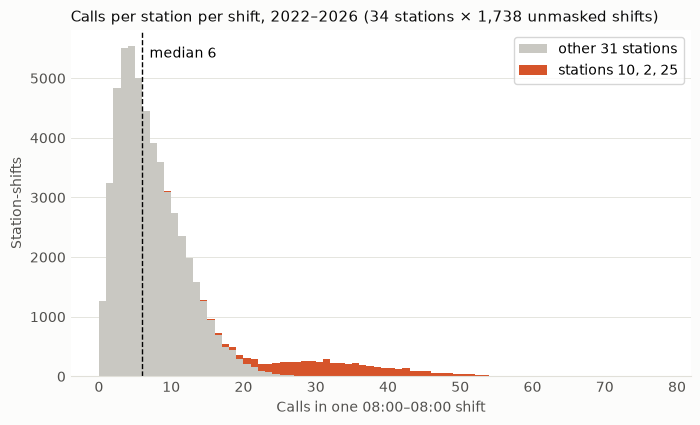

In [30]:
import os
import matplotlib.pyplot as plt

# distribution of the target, for the proposal
target = table.loc[~table['Masked'], 'calls']

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor='#fcfcfb')
busy = table.loc[~table['Masked'], 'Station'].isin(['SFD 10', 'SFD 2', 'SFD 25'])
ax.hist([target[~busy], target[busy]], bins=range(0, target.max() + 2), stacked=True,
        color=['#c9c8c2', '#d6542a'], label=['other 31 stations', 'stations 10, 2, 25'])
ax.axvline(target.median(), color='black', linestyle='--', linewidth=1)
ax.text(target.median() + 1, ax.get_ylim()[1] * 0.92, f'median {target.median():.0f}')
ax.legend()

ax.set_title(f"Calls per station per shift, 2022–2026 ({table['Station'].nunique()} stations × {table.loc[~table['Masked'], 'ShiftDate'].nunique():,} unmasked shifts)",
             loc='left', fontsize=11, color='#0b0b0b')
ax.set_xlabel('Calls in one 08:00–08:00 shift', color='#52514e')
ax.set_ylabel('Station-shifts', color='#52514e')
ax.grid(axis='y', color='#e1e0d9', linewidth=0.6)
ax.set_axisbelow(True)
for side in ['top', 'right', 'left']:
    ax.spines[side].set_visible(False)
ax.spines['bottom'].set_color('#e1e0d9')
ax.tick_params(colors='#52514e', length=0)

os.makedirs('figures', exist_ok=True)
fig.savefig('../figures/target_distribution.png', dpi=200, bbox_inches='tight')
print(f"mean {target.mean():.1f}, variance {target.var():.1f}, 0-call share {(target == 0).mean():.1%}")
plt.show()